# TE-292 — Aula 3: juntando dados de manutenção

## Etapa A — Consumo de peças por motivo de manutenção

**Tempo previsto:** 30 minutos

### O que aprenderemos

- descobrir o que cada linha de uma tabela representa;
- identificar a coluna usada para relacionar tabelas;
- resumir vários eventos em uma linha para cada ativo;
- diferenciar arquivos recebidos de arquivos produzidos pela análise.

Nesta fonte, cada linha representa um evento de consumo:

`ativo + instante + motivo + peça + quantidade`.

A coluna `Asset` identifica o ativo. Ela será nossa **chave de integração**, isto
é, a coluna usada para relacionar informações de tabelas diferentes.

**Pergunta de abertura:** duas linhas com o mesmo `Asset` são necessariamente
repetições indevidas ou podem representar eventos diferentes?

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
%matplotlib inline

DATA_DIR = Path("dados_manutencao")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

source_path = DATA_DIR / "maintenance_part_consumption.csv"
consumption = pd.read_csv(source_path)

print(f"Fonte: {source_path}")
print(f"Dimensão: {consumption.shape[0]:,} linhas × {consumption.shape[1]} colunas")
consumption.head()

Fonte: dados_manutencao/maintenance_part_consumption.csv
Dimensão: 270,830 linhas × 5 colunas


,Asset,Time,Reason,Part,Quantity
0,A311482,0,R417,P361646,1
1,A174613,0,R707,P991287,1
2,A174613,0,R707,P169319,1
3,A060723,0,R193,P184448,0
4,A174613,0,R707,P097048,1


## 1. O que representa cada linha?

O termo **granularidade** indica o nível de detalhe dos dados — em outras
palavras, o que cada linha representa. Nesta tabela, uma linha representa um
evento de consumo, e não um ativo completo. Por isso o mesmo `Asset` aparece
várias vezes.

Antes de resumir os dados, observaremos:

- os nomes e tipos das colunas, chamados em conjunto de **esquema da tabela**;
- os valores ausentes, isto é, campos sem informação registrada;
- a quantidade de ativos, motivos e peças diferentes.

In [13]:
column_summary = pd.DataFrame({
    "tipo": consumption.dtypes.astype(str),
    "campos_vazios": consumption.isna().sum(),
    "valores_diferentes": consumption.nunique(dropna=True),
})

print("Resumo das colunas")
display(column_summary)

print(f"Ativos diferentes: {consumption['Asset'].nunique():,}")
print(f"Motivos diferentes: {consumption['Reason'].nunique():,}")
print(f"Peças diferentes: {consumption['Part'].nunique():,}")


Resumo das colunas


,tipo,campos_vazios,valores_diferentes
Asset,str,0,1913
Time,int64,0,727
Reason,str,0,14
Part,str,0,3192
Quantity,int64,0,191


Ativos diferentes: 1,913
Motivos diferentes: 14
Peças diferentes: 3,192


## 2. Valores muito altos são erros?

Usaremos o **intervalo interquartil (IQR)**, uma regra estatística que ajuda a
sinalizar valores muito afastados da maioria. Esses valores também são chamados
de **outliers**.

Ser sinalizado não significa estar errado. Uma quantidade elevada pode indicar
uma grande intervenção de manutenção. Nesta aula, apenas identificaremos esses
casos; não excluiremos nem alteraremos os registros.

Esse cuidado faz parte da transformação dos dados em um processo **ETL**:

- **Extract — extrair:** ler os dados da fonte;
- **Transform — transformar:** organizar e combinar os dados;
- **Load — carregar:** salvar o resultado para uso posterior.

> Pausa para discussão: que informação adicional seria necessária antes de
> limitar ou excluir uma quantidade elevada?

Limites diagnósticos pelo IQR: [-0.50, 3.50]
Registros fora dos limites: 44,189 (16.32%)
Decisão desta etapa: manter os valores e registrar a ressalva.


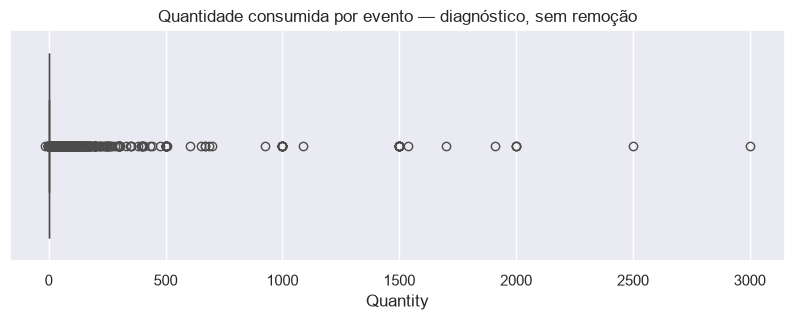

In [14]:
q1, q3 = consumption["Quantity"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outside = ~consumption["Quantity"].between(lower, upper)

print(f"Limites diagnósticos pelo IQR: [{lower:.2f}, {upper:.2f}]")
print(f"Registros fora dos limites: {outside.sum():,} ({outside.mean():.2%})")
print("Decisão desta etapa: manter os valores e registrar a ressalva.")

fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=consumption["Quantity"], ax=ax)
ax.set_title("Quantidade consumida por evento — diagnóstico, sem remoção")
ax.set_xlabel("Quantity")
plt.show()

## 3. De várias linhas para uma linha por ativo

A tabela atual está no **formato longo (`long`)**: cada ativo pode ocupar muitas
linhas. Para juntá-la aos dados de uso e falha, criaremos o **formato largo
(`wide`)**: cada ativo ocupará uma única linha.

Calcularemos a quantidade média consumida para cada combinação de ativo e motivo
`(Asset, Reason)`. Cada motivo (`R044`, `R193`, ...) se tornará uma coluna.

Essa operação é chamada de **tabela dinâmica (`pivot table`)**. Uma célula vazia
significa “não há consumo registrado para esse motivo”; não significa
necessariamente consumo igual a zero.

In [15]:
consumption_by_reason = (
    consumption
    .pivot_table(
        index="Asset",
        columns="Reason",
        values="Quantity",
        aggfunc="mean",
    )
    .sort_index(axis=1)
    .reset_index()
)
consumption_by_reason.columns.name = None

assert consumption_by_reason["Asset"].is_unique

output_path = OUTPUT_DIR / "maintenance_part_consumption_by_reason.csv"
consumption_by_reason.to_csv(output_path, index=False)

print(f"Tabela derivada: {consumption_by_reason.shape[0]:,} ativos × "
      f"{consumption_by_reason.shape[1] - 1} motivos")
print(f"Salva em: {output_path}")
consumption_by_reason.head()

Tabela derivada: 1,913 ativos × 14 motivos
Salva em: output/maintenance_part_consumption_by_reason.csv


,Asset,R044,R064,R119,R193,R364,R396,R417,R446,R565,R575,R606,R707,R782,R783
0,A000204,NaN,NaN,0.857143,1.629630,1.000000,NaN,NaN,1.000,3.785714,NaN,NaN,2.229885,NaN,NaN
1,A000270,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN
2,A000463,NaN,NaN,1.000000,2.086957,1.000000,NaN,NaN,1.000,NaN,NaN,NaN,3.318841,NaN,1.5
3,A000495,NaN,NaN,0.800000,2.928571,1.444444,NaN,NaN,1.625,8.040816,NaN,NaN,2.164179,NaN,NaN
4,A001201,NaN,NaN,NaN,1.166667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.900000,NaN,NaN


## Ponto de verificação da etapa A

Um **checkpoint** é um resultado intermediário salvo para ser usado na etapa
seguinte.

- **Dado primário:** `maintenance_part_consumption.csv`, recebido como fonte;
- **Transformação:** eventos → consumo médio por motivo e ativo;
- **Dado derivado:** `output/maintenance_part_consumption_by_reason.csv`, criado
  pelo notebook;
- **Coluna de ligação:** `Asset`, agora com um único valor por linha.

**Antes de seguir para B:** por que não substituímos automaticamente os campos
vazios por zero?

## Anexo — Falhas nos registros de manutenção (`maintenance_failures.csv`)

Até aqui trabalhamos apenas com o consumo de peças. Nesta seção extra,
carregaremos `maintenance_failures.csv` — a fonte que registra, por ativo, se
houve falha (`failure_bin = 1`) ou não (`failure_bin = 0`) — e faremos as
mesmas checagens de qualidade usadas na etapa 1, agora cruzando as chaves
`Asset` com `maintenance_part_consumption.csv` e com
`Asset_new_informations.csv`.

In [16]:
failures_path = DATA_DIR / "maintenance_failures.csv"
failures = pd.read_csv(failures_path)

print(f"Fonte: {failures_path}")
print(f"Dimensão: {failures.shape[0]:,} linhas × {failures.shape[1]} colunas\n")

failures_summary = pd.DataFrame({
    "tipo": failures.dtypes.astype(str),
    "campos_vazios": failures.isna().sum(),
    "valores_diferentes": failures.nunique(dropna=True),
})
print("Resumo das colunas")
display(failures_summary)

print(f"Ativos repetidos: {failures['Asset'].duplicated().sum()}")
print(f"Valores fora de {{0, 1}} em failure_bin: "
      f"{(~failures['failure_bin'].isin([0, 1])).sum()}")
print("\nDistribuição de failure_bin")
print(failures["failure_bin"].value_counts().to_string())
print(f"Taxa de falha: {failures['failure_bin'].mean():.2%}")

Fonte: dados_manutencao/maintenance_failures.csv
Dimensão: 1,805 linhas × 2 colunas

Resumo das colunas


,tipo,campos_vazios,valores_diferentes
Asset,str,0,1805
failure_bin,int64,0,2


Ativos repetidos: 0
Valores fora de {0, 1} em failure_bin: 0

Distribuição de failure_bin
failure_bin
0    1357
1     448
Taxa de falha: 24.82%


O arquivo em si está limpo: sem `Asset` repetido, sem campo vazio, e
`failure_bin` só assume 0 ou 1. O problema aparece quando cruzamos essa chave
com as outras fontes.

In [17]:
consumption_assets = set(consumption["Asset"])
failure_assets = set(failures["Asset"])

only_in_consumption = consumption_assets - failure_assets
only_in_failures = failure_assets - consumption_assets

print(f"Ativos em consumo sem registro de falha:  {len(only_in_consumption):,}")
print(f"Ativos com falha sem evento de consumo:   {len(only_in_failures):,}")

lost_events = consumption[consumption["Asset"].isin(only_in_consumption)]
print(f"\nEventos de consumo 'órfãos' (sem resposta de falha conhecida): "
      f"{len(lost_events):,} linhas, {lost_events['Asset'].nunique()} ativos")
print("Motivos mais comuns nesses eventos órfãos:")
print(lost_events["Reason"].value_counts().head())

Ativos em consumo sem registro de falha:  108
Ativos com falha sem evento de consumo:   0

Eventos de consumo 'órfãos' (sem resposta de falha conhecida): 6,466 linhas, 108 ativos
Motivos mais comuns nesses eventos órfãos:
Reason
R707    4342
R565    1094
R446     357
R193     259
R364     187
Name: count, dtype: int64
